# Week 1–2: Propensity score matching — a balance diagnostic

**Project: EconoCausal.** This notebook checks whether customers receiving a campaign email resemble customers receiving no email **before** the campaign.

Imagine comparing two classrooms after giving one a learning game. You first check whether the classrooms had similar starting skills. Matching finds comparable starting profiles; it cannot reveal every unseen difference.

The supplied Hillstrom data records randomized **Men’s email, Women’s email, and No E-Mail**, not dollar discounts. We make two separate email-versus-no-email comparisons. We do not invent discount amounts or claim an observed individual causal effect.

**Review verdict:** the previous notebook correctly used baseline features, training data, and nearest-neighbour matching with replacement. This version removes dependencies on `common.py` and saved encoders, fixes the changing balance denominator, handles numerical/empty-match cases, and adds overlap, retention, control reuse, and detailed balance checks.

Run this notebook from your repository or a subfolder. It needs `data/raw/hillstrom.csv`. It writes diagnostic files only under `results/propensity_matching/`; it does not replace your preprocessing or DML training data.

In [1]:
from pathlib import Path
import json
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial import cKDTree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

SEED = 42
roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in roots if (p / "data/raw/hillstrom.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the project folder containing data/raw/hillstrom.csv.")
OUTPUT = ROOT / "results/propensity_matching"
OUTPUT.mkdir(parents=True, exist_ok=True)
source = ROOT / "data/raw/hillstrom.csv"
data = pd.read_csv(source)
print("Rows and columns:", data.shape)
print("Source SHA256:", hashlib.sha256(source.read_bytes()).hexdigest())

Rows and columns: (64000, 12)
Source SHA256: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


## 1. Validate the data and reserve the evaluation sample

We keep identical-looking rows because there is no customer identifier proving they are duplicate people. `source_row` only identifies a CSV row. Outcomes (`visit`, `conversion`, `spend`) never enter the matching model. We use the same 70/30 treatment-stratified split and seed 42 as the preprocessing notebook; the 30% evaluation sample stays untouched.

The campaign's random assignment is a study-design assumption from the guide; balance alone cannot establish randomization.

In [2]:
BASELINE = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
OUTCOMES = ["visit", "conversion", "spend"]
required = BASELINE + OUTCOMES + ["segment"]
assert set(required).issubset(data.columns), "Required columns are missing."
assert not data[required].isna().any().any(), "Review missing values before matching."
assert data["recency"].between(1, 12).all()
assert (data["history"] >= 0).all()
for name in ["mens", "womens", "newbie", "visit", "conversion"]:
    assert data[name].isin([0, 1]).all(), f"Invalid binary values: {name}"
assert np.isfinite(data[["history", "spend"]].to_numpy()).all()
assert (data["spend"] >= 0).all()
assert (data["conversion"] <= data["visit"]).all()
ARMS = {"No E-Mail": 0, "Mens E-Mail": 1, "Womens E-Mail": 2}
assert set(data["segment"].unique()) == set(ARMS)
data["treatment"] = data["segment"].map(ARMS)
data["source_row"] = np.arange(len(data))
data["zip_code"] = data["zip_code"].replace({"Surburban": "Suburban"})
train, holdout = train_test_split(data, test_size=0.30, random_state=SEED,
                                 stratify=data["treatment"])
train = train.copy()
assert set(train.source_row).isdisjoint(holdout.source_row)
display(pd.DataFrame({"all_rows": data.segment.value_counts(),
                      "training_rows": train.segment.value_counts(),
                      "held_out_rows": holdout.segment.value_counts()}))

,all_rows,training_rows,held_out_rows
segment,,,
Womens E-Mail,21387,14971,6416
Mens E-Mail,21307,14915,6392
No E-Mail,21306,14914,6392


## 2. Use only information available before sending the email

`history_log1p` makes large past spending values less dominant; `recency_band` groups the months since a past purchase; `prior_interest_count` counts the two prior purchase categories. These are deterministic summaries of baseline information, not new causal confounders. We omit `history_segment` because it bins spending already represented by history.

Categories become 0/1 columns. Scaling is used for logistic regression, while balance is calculated on the original feature values. There is no outcome balancing, synthetic oversampling, or removal of legitimate high spenders.

In [3]:
train["history_log1p"] = np.log1p(train["history"])
train["recency_band"] = pd.cut(train["recency"], bins=[0, 4, 8, 12],
                               labels=["1–4 months", "5–8 months", "9–12 months"])
train["prior_interest_count"] = train["mens"] + train["womens"]
numeric = ["recency", "history", "mens", "womens", "newbie",
           "history_log1p", "prior_interest_count"]
categorical = ["zip_code", "channel", "recency_band"]
features = pd.get_dummies(train[numeric + categorical], columns=categorical,
                          drop_first=False, dtype=float).astype(float)
assert np.isfinite(features.to_numpy()).all()
assert not set(OUTCOMES + ["treatment", "source_row"]).intersection(features.columns)
print("Baseline features used for matching:")
print(features.columns.tolist())

Baseline features used for matching:
['recency', 'history', 'mens', 'womens', 'newbie', 'history_log1p', 'prior_interest_count', 'zip_code_Rural', 'zip_code_Suburban', 'zip_code_Urban', 'channel_Multichannel', 'channel_Phone', 'channel_Web', 'recency_band_1–4 months', 'recency_band_5–8 months', 'recency_band_9–12 months']


## 3. Define matching and a comparable balance measure

A propensity score is the predicted probability of receiving the email given baseline information. Within each email/control pair the design probability is about **1/2** (in the full three-arm study each arm is about **1/3**). Fitted scores may vary through finite-sample noise even in a randomized study.

We match each treated row to the nearest control on the log-odds of its score. The caliper is **0.2 × the pooled pre-match standard deviation of log-odds across the two groups**, a conventional starting choice, not a guarantee of good balance. Matching uses replacement: one control can represent several treated rows. Unmatched treated rows are reported.

For each feature, standardized mean difference (SMD) is:

`(treated mean − control mean) / sqrt((treated variance + control variance) / 2)`.

The denominator is calculated **once before matching** and reused afterwards. Thus changes in the graph reflect changes in mean differences, not a changing ruler. For constant features, identical means give zero; different means give infinity and must be investigated. Absolute SMD below 0.1 is a practical diagnostic guideline, not a causal proof.

In [4]:
def fixed_smd(treated, control, scale):
    difference = treated.mean(axis=0) - control.mean(axis=0)
    result = np.divide(difference, scale, out=np.zeros_like(difference), where=scale > 0)
    result[(scale == 0) & (difference != 0)] = np.inf
    return result


def match_nearest(logits, treatment, caliper):
    treated = np.flatnonzero(treatment == 1)
    controls = np.flatnonzero(treatment == 0)
    if len(treated) == 0 or len(controls) == 0:
        raise ValueError("Both treatment and control rows are required.")
    distance, nearest = cKDTree(logits[controls, None]).query(logits[treated, None])
    accepted = distance <= caliper
    return treated[accepted], controls[nearest[accepted]], distance[accepted]

# Small checks verify edge cases without using any campaign outcomes.
assert np.isinf(fixed_smd(np.ones((2, 1)), np.zeros((2, 1)), np.zeros(1))[0])
assert fixed_smd(np.zeros((2, 1)), np.zeros((2, 1)), np.zeros(1))[0] == 0
assert len(match_nearest(np.array([0., 10.]), np.array([0, 1]), 0.1)[0]) == 0
assert len(match_nearest(np.zeros(3), np.array([0, 1, 1]), 0)[0]) == 2
print("Constant-feature, no-match, and replacement checks passed.")

Constant-feature, no-match, and replacement checks passed.


## 4. Run both comparisons without looking at outcomes

Empirical common support is the intersection of the two groups' fitted score ranges. We report rows outside it rather than silently trimming them. The caliper itself decides which pairs are retained. With replacement, repeated controls must remain repeated when calculating matched balance.

Control effective sample size is `(sum of reuse counts)² / sum of squared reuse counts`. Heavy reuse reduces this number. It is a diagnostic of weight concentration, not a confidence interval.

In [5]:
summaries = []
analyses = {}
for arm, label in [(1, "Mens E-Mail"), (2, "Womens E-Mail")]:
    pair = train.loc[train.treatment.isin([0, arm])]
    x = features.loc[pair.index].to_numpy()
    t = (pair.treatment == arm).astype(int).to_numpy()
    if min(np.bincount(t)) < 2:
        raise ValueError("Each group needs at least two rows for variance calculations.")
    scaled = StandardScaler().fit_transform(x)
    model = LogisticRegression(max_iter=2000, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model.fit(scaled, t)
    scores = model.predict_proba(scaled)[:, 1]
    # Numerical clipping only; this does not remove rows or change their treatment.
    safe_scores = np.clip(scores, 1e-6, 1 - 1e-6)
    logits = np.log(safe_scores / (1 - safe_scores))
    logit_sd = np.sqrt((logits[t == 1].var(ddof=1) + logits[t == 0].var(ddof=1)) / 2)
    caliper = 0.2 * logit_sd
    mt, mc, distances = match_nearest(logits, t, caliper)
    if len(mt) == 0:
        raise ValueError(f"{label}: no pairs met the caliper. No balance success can be reported.")
    scale = np.sqrt((x[t == 1].var(axis=0, ddof=1) + x[t == 0].var(axis=0, ddof=1)) / 2)
    before = fixed_smd(x[t == 1], x[t == 0], scale)
    after = fixed_smd(x[mt], x[mc], scale)
    balance = pd.DataFrame({"feature": features.columns, "smd_before": before,
                            "smd_after": after, "fixed_pre_match_sd": scale})
    unique_controls, reuse = np.unique(mc, return_counts=True)
    ess = float(reuse.sum() ** 2 / np.square(reuse).sum())
    overlap_low = max(scores[t == 1].min(), scores[t == 0].min())
    overlap_high = min(scores[t == 1].max(), scores[t == 0].max())
    outside = (scores < overlap_low) | (scores > overlap_high)
    matched = pd.DataFrame({"treated_source_row": pair.source_row.to_numpy()[mt],
                            "control_source_row": pair.source_row.to_numpy()[mc],
                            "logit_distance": distances})
    assert (distances <= caliper).all()
    assert matched.treated_source_row.is_unique
    assert set(matched.control_source_row).issubset(train.source_row)
    # Repeated-row balance agrees with frequency-weighted control balance.
    assert np.allclose(x[mc].mean(axis=0), np.average(x[unique_controls], axis=0, weights=reuse))
    summary = {"arm": label, "treated_before": int(t.sum()),
               "controls_before": int((t == 0).sum()), "matched_treated": len(mt),
               "unmatched_treated": int(t.sum()) - len(mt),
               "retained_percent": 100 * len(mt) / int(t.sum()),
               "unique_controls": len(unique_controls), "control_ESS": ess,
               "maximum_control_reuse": int(reuse.max()), "logit_caliper": float(caliper),
               "overlap_low": float(overlap_low), "overlap_high": float(overlap_high),
               "treated_outside_overlap": int(outside[t == 1].sum()),
               "controls_outside_overlap": int(outside[t == 0].sum()),
               "max_abs_SMD_before": float(abs(before).max()),
               "max_abs_SMD_after": float(abs(after).max())}
    summaries.append(summary)
    analyses[label] = {"scores": scores, "t": t, "balance": balance}
    prefix = "mens" if arm == 1 else "womens"
    balance.to_csv(OUTPUT / f"{prefix}_balance.csv", index=False)
    matched.to_csv(OUTPUT / f"{prefix}_matched_rows.csv", index=False)
    pd.DataFrame({"control_source_row": pair.source_row.to_numpy()[unique_controls],
                  "times_used": reuse}).to_csv(OUTPUT / f"{prefix}_control_reuse.csv", index=False)

summary_table = pd.DataFrame(summaries)
display(summary_table.T)
summary_table.to_csv(OUTPUT / "matching_summary.csv", index=False)

,0,1
arm,Mens E-Mail,Womens E-Mail
treated_before,14915,14971
controls_before,14914,14914
matched_treated,14910,14969
unmatched_treated,5,2
retained_percent,99.966477,99.986641
unique_controls,7466,7534
control_ESS,4193.226573,4261.767712
maximum_control_reuse,24,23
logit_caliper,0.006445,0.005261


## 5. Inspect overlap and every feature's balance

Left: overlapping histograms mean comparable fitted assignment probabilities are available. Right: each dot is one baseline feature. Smaller absolute SMD means closer group means. The orange dot need not improve on blue: the original randomized groups may already be very similar.

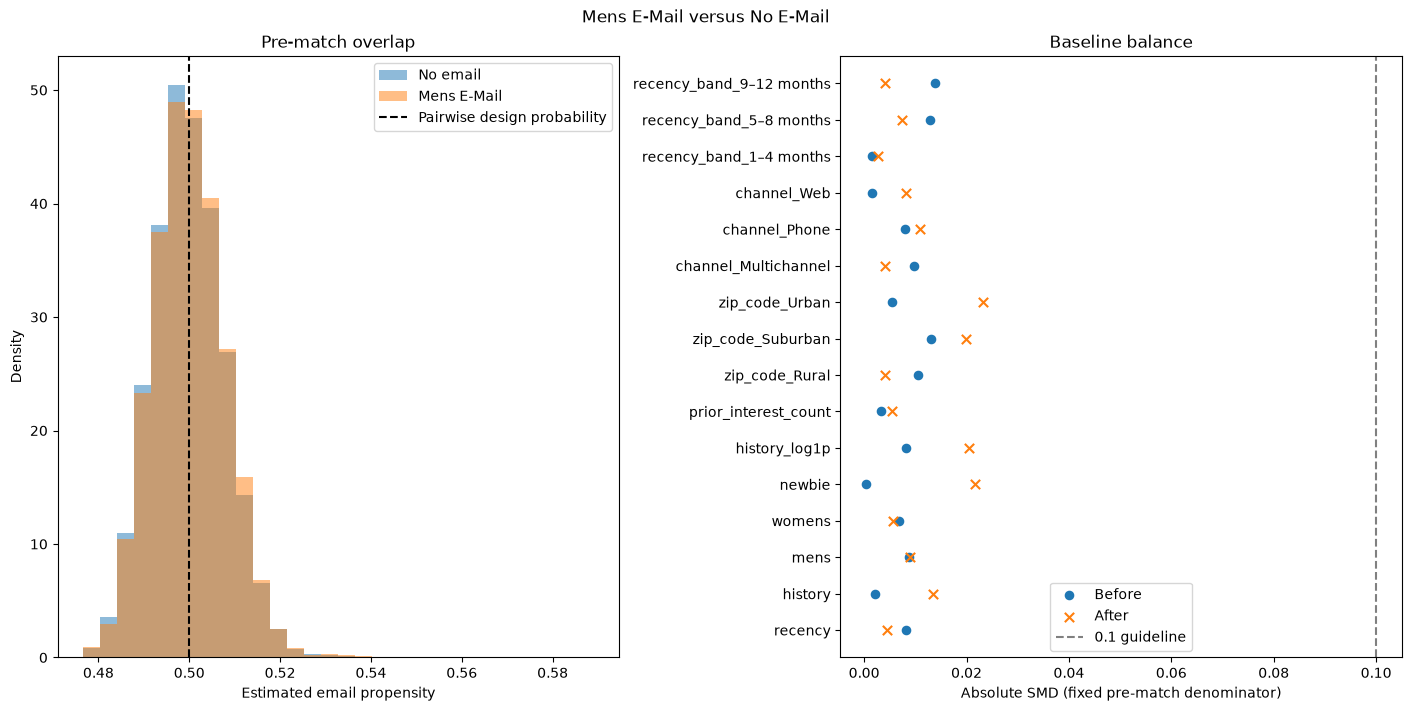

,feature,smd_before,smd_after,fixed_pre_match_sd
0,recency,0.0083,-0.0044,3.5081
1,history,0.0020,0.0134,254.4896
2,mens,-0.0088,0.0090,0.4972
3,womens,0.0068,-0.0057,0.4976
4,newbie,-0.0003,0.0216,0.5000
5,history_log1p,-0.0082,0.0204,1.0179
6,prior_interest_count,-0.0033,0.0055,0.3033
7,zip_code_Rural,0.0106,-0.0041,0.3604
8,zip_code_Suburban,-0.0130,-0.0198,0.4971
9,zip_code_Urban,0.0054,0.0231,0.4900


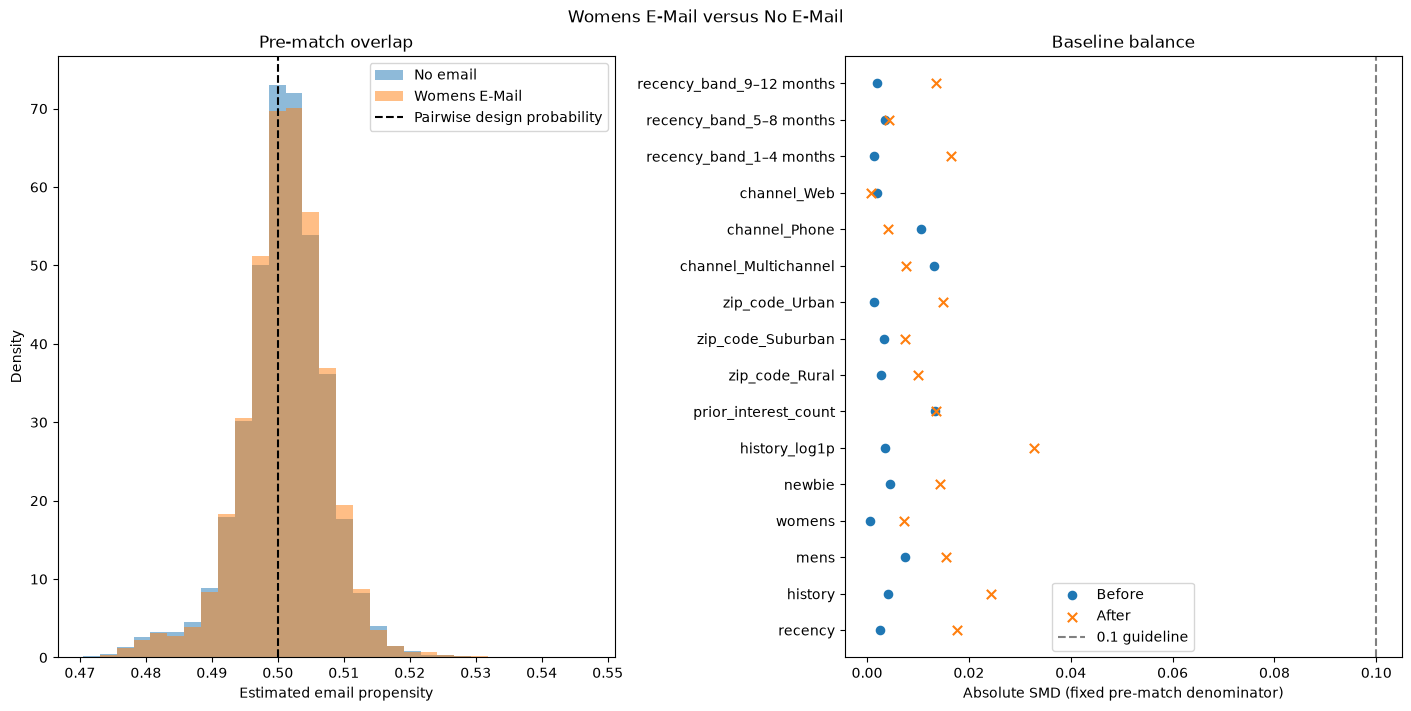

,feature,smd_before,smd_after,fixed_pre_match_sd
0,recency,-0.0025,-0.0178,3.5072
1,history,0.0042,0.0243,252.7296
2,mens,-0.0075,0.0155,0.4971
3,womens,-0.0006,-0.0072,0.4978
4,newbie,-0.0045,0.0143,0.5000
5,history_log1p,0.0035,0.0329,1.0147
6,prior_interest_count,-0.0133,0.0135,0.3013
7,zip_code_Rural,-0.0027,-0.0101,0.3581
8,zip_code_Suburban,0.0033,-0.0074,0.4975
9,zip_code_Urban,-0.0013,0.0149,0.4897


In [6]:
for label, result in analyses.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
    scores, t = result["scores"], result["t"]
    bins = np.linspace(scores.min(), scores.max(), 31)
    for group, name in [(0, "No email"), (1, label)]:
        axes[0].hist(scores[t == group], bins=bins, density=True, alpha=0.5, label=name)
    axes[0].axvline(0.5, color="black", linestyle="--", label="Pairwise design probability")
    axes[0].set(xlabel="Estimated email propensity", ylabel="Density", title="Pre-match overlap")
    axes[0].legend()
    b = result["balance"]
    positions = np.arange(len(b))
    axes[1].scatter(b.smd_before.abs(), positions, label="Before", s=35)
    axes[1].scatter(b.smd_after.abs(), positions, label="After", marker="x", s=45)
    axes[1].axvline(0.1, color="grey", linestyle="--", label="0.1 guideline")
    axes[1].set_yticks(positions, b.feature)
    axes[1].set(xlabel="Absolute SMD (fixed pre-match denominator)", title="Baseline balance")
    axes[1].legend()
    fig.suptitle(label + " versus No E-Mail")
    fig.savefig(OUTPUT / ("mens_diagnostics.png" if label.startswith("Mens") else "womens_diagnostics.png"), dpi=130)
    plt.show()
    display(b.round(4))

## 6. Report what actually happened

These messages are computed from the results rather than promising matching will help. A well-balanced matched sample supports comparability on the **measured** baseline features; it does not rule out hidden confounding or prove that email caused an outcome.

In [7]:
for row in summaries:
    direction = "decreased" if row["max_abs_SMD_after"] < row["max_abs_SMD_before"] else "did not decrease"
    print(f"{row['arm']}: kept {row['retained_percent']:.2f}% of treated rows; "
          f"used {row['unique_controls']:,} unique controls (ESS {row['control_ESS']:,.0f}).")
    print(f"  Maximum absolute SMD {direction}: {row['max_abs_SMD_before']:.4f} before, "
          f"{row['max_abs_SMD_after']:.4f} after.")
    print("  All measured features below 0.1 after matching:", row["max_abs_SMD_after"] < 0.1)
print("Checks passed: no held-out rows, no outcome predictors, caliper respected, reuse weights correct.")
print("Diagnostic tables and figures saved to results/propensity_matching/.")

Mens E-Mail: kept 99.97% of treated rows; used 7,466 unique controls (ESS 4,193).
  Maximum absolute SMD did not decrease: 0.0138 before, 0.0231 after.
  All measured features below 0.1 after matching: True
Womens E-Mail: kept 99.99% of treated rows; used 7,534 unique controls (ESS 4,262).
  Maximum absolute SMD did not decrease: 0.0133 before, 0.0329 after.
  All measured features below 0.1 after matching: True
Checks passed: no held-out rows, no outcome predictors, caliper respected, reuse weights correct.
Diagnostic tables and figures saved to results/propensity_matching/.


## What to tell your manager

“We checked whether the email and no-email groups had similar customer characteristics before the campaign. We matched on past shopping information and measured balance before and after. We also checked how many customers were left out and how often the same comparison customer was reused. Since this was a randomized email experiment, matching is an extra diagnostic; it may not improve an already balanced sample.”

**Next step:** fit DML on the original randomized training sample from preprocessing, not these matched rows. Use untouched evaluation data for uplift/Qini evaluation. If a later analysis estimates an effect from these matches, it concerns the retained treated population, not automatically the full-population ATE; uncertainty must account for reused controls. This notebook deliberately does not estimate individual treatment effects, prove immunity to hidden confounding, or optimize discounts.

### Requirement alignment and sources
- Supplied project images: propensity score matching and balancing historical data.
- Supplied EconoCausal Project Guide, dataset and technical guide sections: Hillstrom is randomized; matching remains a diagnostic exercise.
- [Austin (2011), optimal caliper widths](https://doi.org/10.1002/pst.433): rationale for a 0.2 SD logit caliper; the practical choice still needs diagnostics.
- [cobalt FAQ: standardized differences](https://ngreifer.github.io/cobalt/articles/faq.html): using a consistent standardization factor when comparing balance.

**Environment:** Python with numpy, pandas, scipy, scikit-learn, matplotlib and a Jupyter kernel. If imports fail, select the project's Python kernel in VS Code before installing dependencies. No DoWhy import is needed for this matching step; DoWhy is used for the causal graph and subsequent refutation work.